# Bluff Poker: Should I Raise or Call?

**The game**
- **4 players** start with **2 cards** each (set `NUM_PLAYERS` below to 2 to 5). Nobody sees anyone else's cards.
- Claims are poker hands made from **all the cards on the table**, not just yours.
- On your turn you either **RAISE** (claim a higher hand) or **CALL** (say the last claim isn't there).
- On a call everyone reveals. If the claim is there, the caller loses; if not, the claimer loses.
- The loser gets **one more card** next round. At **5 cards you're out**. Last player standing wins.

**The question:** given my cards, how many cards are on the table, and the current claim, should I raise or call?

**The plan**
1. Use **Monte Carlo simulation** to estimate how likely a claim is.
2. Use Monte Carlo again to estimate how risky a raise is: will the next player call me, and will I be wrong?
3. Simulate thousands of decisions, record which action actually won, and train **decision trees** on them.
4. Have the tree play full games against simpler strategies.
5. Type in your own cards and ask the tree.

In [19]:
import math
import random
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

random.seed(163)
np.random.seed(163)

# Chart styling: quiet axes, light grid
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE = SERIES[0], SERIES[1]

## 1. Cards and claims

In [20]:
RANKS = list(range(2, 15))  # 11=J, 12=Q, 13=K, 14=A
SUITS = "SHDC"
DECK = [(r, s) for r in RANKS for s in SUITS]
RANK_NAME = {**{r: str(r) for r in range(2, 11)}, 11: "J", 12: "Q", 13: "K", 14: "A"}
MAX_CARDS = 5  # reach this many cards and you're out
NUM_PLAYERS = 4  # players at the start of a game (2 to 5); rerun the whole notebook after changing it
assert 2 <= NUM_PLAYERS <= 5, "the tournament in section 6 has 5 strategies, so use 2 to 5 players"
MAX_UNSEEN = (NUM_PLAYERS - 1) * (MAX_CARDS - 1)  # most cards you can't see: everyone else holding 4

CATEGORIES = ["high card", "pair", "two pair", "three of a kind", "straight",
              "flush", "full house", "four of a kind", "straight flush"]
CARDS_NEEDED = {"high card": 1, "pair": 2, "two pair": 4, "three of a kind": 3, "straight": 5,
                "flush": 5, "full house": 5, "four of a kind": 4, "straight flush": 5}


def straight_ranks(high):
    """Ranks in a straight with this high card (a 5-high straight uses the ace low)."""
    return [14, 2, 3, 4, 5] if high == 5 else list(range(high - 4, high + 1))


# A claim is (category, rank1, rank2).  Examples:
#   ("pair", 11, 0)        a pair of jacks
#   ("two pair", 13, 4)    kings and fours
#   ("full house", 9, 2)   nines full of twos
#   ("straight", 10, 0)    a 10-high straight
#   ("flush", 0, 0)        any five cards of one suit
ALL_CLAIMS = sorted(
    [("high card", r, 0) for r in RANKS] + [("pair", r, 0) for r in RANKS]
    + [("two pair", a, b) for a in RANKS for b in RANKS if a > b]
    + [("three of a kind", r, 0) for r in RANKS] + [("straight", h, 0) for h in range(5, 15)]
    + [("flush", 0, 0)] + [("full house", a, b) for a in RANKS for b in RANKS if a != b]
    + [("four of a kind", r, 0) for r in RANKS] + [("straight flush", h, 0) for h in range(5, 15)],
    key=lambda c: (CATEGORIES.index(c[0]), c[1], c[2]))
CLAIM_INDEX = {c: i for i, c in enumerate(ALL_CLAIMS)}
CATEGORY_START = {cat: min(i for i, c in enumerate(ALL_CLAIMS) if c[0] == cat) for cat in CATEGORIES}


def claim_name(claim):
    cat, a, b = claim
    n = RANK_NAME.get
    return {"high card": f"a {n(a)}", "pair": f"pair of {n(a)}s", "two pair": f"two pair, {n(a)}s and {n(b)}s",
            "three of a kind": f"three {n(a)}s", "straight": f"{n(a)}-high straight", "flush": "a flush",
            "full house": f"{n(a)}s full of {n(b)}s", "four of a kind": f"four {n(a)}s",
            "straight flush": f"{n(a)}-high straight flush"}[cat]


def claim_is_true(claim, cards):
    """Does the claimed hand exist among these cards?"""
    cat, r1, r2 = claim
    counts = Counter(r for r, _ in cards)
    if cat == "high card":
        return counts[r1] >= 1
    if cat == "pair":
        return counts[r1] >= 2
    if cat == "two pair":
        return counts[r1] >= 2 and counts[r2] >= 2
    if cat == "three of a kind":
        return counts[r1] >= 3
    if cat == "straight":
        return all(counts[r] >= 1 for r in straight_ranks(r1))
    if cat == "flush":
        return max(Counter(s for _, s in cards).values()) >= 5
    if cat == "full house":
        return counts[r1] >= 3 and counts[r2] >= 2
    if cat == "four of a kind":
        return counts[r1] >= 4
    have = set(cards)  # straight flush
    return any(all((r, s) in have for r in straight_ranks(r1)) for s in SUITS)


def my_help(claim, mine):
    """How many of MY cards count toward the claimed hand."""
    cat, r1, r2 = claim
    ranks = [r for r, _ in mine]
    if cat in ("high card", "pair", "three of a kind", "four of a kind"):
        return min(ranks.count(r1), CARDS_NEEDED[cat])
    if cat == "two pair":
        return min(ranks.count(r1), 2) + min(ranks.count(r2), 2)
    if cat == "full house":
        return min(ranks.count(r1), 3) + min(ranks.count(r2), 2)
    if cat == "straight":
        return len(set(ranks) & set(straight_ranks(r1)))
    if cat == "flush":
        return min(max(Counter(s for _, s in mine).values()), 5)
    return max(len({r for r, s in mine if s == suit and r in straight_ranks(r1)}) for suit in SUITS)

## 2. Monte Carlo: how likely is a claim?

You can only see your own cards. To estimate how likely a claim is:
1. Take your cards out of the deck.
2. Deal the *other* players' cards at random from what's left.
3. Check whether the claim is on the table, and repeat a few thousand times.

The fraction of deals where the claim is there is the probability.

In [21]:
def mc_p_true(claim, mine, unseen, trials=3000):
    rest = [c for c in DECK if c not in mine]
    return sum(claim_is_true(claim, mine + random.sample(rest, unseen)) for _ in range(trials)) / trials


# Example: I hold two kings, everyone else holds 2 cards each, and someone claims three kings
print(mc_p_true(("three of a kind", 13, 0), [(13, "S"), (13, "H")], unseen=2 * (NUM_PLAYERS - 1)))
# ...and the same claim when everyone else holds 4 cards each (they've lost a lot)
print(mc_p_true(("three of a kind", 13, 0), [(13, "S"), (13, "H")], unseen=MAX_UNSEEN))

0.232
0.4126666666666667


### Making it fast
Running 3,000 deals for every decision would make the later simulations take hours, so we use two shortcuts:

- **Claims that only care about ranks** (high card, pair, two pair, three/four of a kind, full house) can be
  computed *exactly* by counting combinations, the same math as drawing colored marbles from a bag.
  We check it against Monte Carlo below.
- **Straights and flushes** are messy to count exactly, so we run one big Monte Carlo up front and save the results
  in a lookup table by **(claim type, how many of my cards help, how many cards I can't see)**.

In [22]:
RANK_ONLY = {"high card", "pair", "two pair", "three of a kind", "full house", "four of a kind"}
NEED = {"high card": (1, 0), "pair": (2, 0), "three of a kind": (3, 0), "four of a kind": (4, 0),
        "two pair": (2, 2), "full house": (3, 2)}


def exact_p(claim, mine, unseen):
    """Exact P(claim is there) for rank-only claims (a multivariate hypergeometric)."""
    cat, r1, r2 = claim
    held = Counter(r for r, _ in mine)
    n1, n2 = NEED[cat]
    need1, need2 = max(0, n1 - held[r1]), max(0, n2 - held[r2]) if n2 else 0
    k1, k2 = 4 - held[r1], (4 - held[r2]) if n2 else 0  # copies still out there
    deck_left = 52 - len(mine)
    total = math.comb(deck_left, unseen)
    p = 0
    for x1 in range(need1, min(k1, unseen) + 1):
        for x2 in range(need2, min(k2, unseen - x1) + 1):
            p += math.comb(k1, x1) * math.comb(k2, x2) * math.comb(deck_left - k1 - k2, unseen - x1 - x2)
    return p / total


def exact_flush(mine, unseen):
    """Exact P(some suit has 5+ cards): walk through every way the unseen cards could split across the 4 suits."""
    held = [sum(s == suit for _, s in mine) for suit in SUITS]
    left = [13 - h for h in held]
    total = math.comb(52 - len(mine), unseen)

    def walk(i, remaining, ways, flush):
        if i == 4:
            return ways if (remaining == 0 and flush) else 0
        return sum(walk(i + 1, remaining - x, ways * math.comb(left[i], x), flush or held[i] + x >= 5)
                   for x in range(min(left[i], remaining) + 1))

    return walk(0, unseen, 1, False) / total


def random_claim(mine=None, cats=CATEGORIES):
    """A random claim. Half the time it's built from one of my ranks, so we see plenty of 'my cards help' cases."""
    cat = random.choice(cats)
    r1, r2 = random.sample(RANKS, 2)
    if mine and random.random() < 0.5:
        r1 = random.choice(mine)[0]
        if r2 == r1:
            r2 = random.choice([r for r in RANKS if r != r1])
    if cat == "two pair" and r1 < r2:
        r1, r2 = r2, r1
    if cat in ("straight", "straight flush"):
        return (cat, max(5, min(14, r1 + random.randint(0, 4))), 0)
    if cat == "flush":
        return (cat, 0, 0)
    if cat in ("two pair", "full house"):
        return (cat, r1, r2)
    return (cat, r1, 0)


def build_table(samples):
    hits, counts = defaultdict(int), defaultdict(int)
    for _ in range(samples):
        my_n, unseen = random.randint(2, 4), random.randint(2, MAX_UNSEEN)
        table = random.sample(DECK, my_n + unseen)
        mine = table[:my_n]
        claim = random_claim(mine, cats=["straight", "straight flush"])
        key = (CATEGORIES.index(claim[0]), my_help(claim, mine), unseen)
        counts[key] += 1
        hits[key] += claim_is_true(claim, table)
    rows = [{"claim_level": k[0], "my_help": k[1], "unseen": k[2], "n": counts[k], "hits": hits[k]}
            for k in counts]
    return pd.DataFrame(rows)


start = time.time()
table_df = build_table(500_000)
print(f"straight table built from 500,000 deals in {time.time() - start:.0f}s")

# Smooth each cell with its neighbours (one more / one fewer unseen card) to cut the noise in rare cells
idx = table_df.set_index(["claim_level", "my_help", "unseen"])[["hits", "n"]]
table_df["p"] = [
    (r.hits + sum(idx.hits.get((r.claim_level, r.my_help, r.unseen + d), 0) for d in (-1, 1)) / 2 + 0.5)
    / (r.n + sum(idx.n.get((r.claim_level, r.my_help, r.unseen + d), 0) for d in (-1, 1)) / 2 + 1)
    for r in table_df.itertuples()]
P_TABLE = {(r.claim_level, r.my_help, r.unseen): r.p for r in table_df.itertuples()}


FLUSH_CACHE = {}


def p_true(claim, mine, unseen):
    """Fast P(claim is there) given MY cards.  unseen = how many cards the other players hold."""
    if claim[0] in RANK_ONLY:
        return exact_p(claim, mine, unseen)
    if claim[0] == "flush":
        key = (tuple(sorted(Counter(s for _, s in mine).values())), len(mine), unseen)
        if key not in FLUSH_CACHE:
            FLUSH_CACHE[key] = exact_flush(mine, unseen)
        return FLUSH_CACHE[key]
    lvl, h = CATEGORIES.index(claim[0]), my_help(claim, mine)
    if h >= CARDS_NEEDED[claim[0]]:
        return 1.0  # my own cards already make it
    return P_TABLE.get((lvl, h, unseen), 0.0)


# Check the shortcuts against direct Monte Carlo
for claim, mine, unseen in [(("three of a kind", 13, 0), [(13, "S"), (13, "H")], 8),
                            (("pair", 11, 0), [(4, "S"), (9, "H")], 8),
                            (("full house", 9, 4), [(9, "S"), (4, "H"), (4, "D")], 12),
                            (("straight", 10, 0), [(10, "S"), (8, "H")], 8),
                            (("flush", 0, 0), [(4, "S"), (9, "S"), (2, "S")], 6)]:
    print(f"{claim_name(claim):>22}: shortcut {p_true(claim, mine, unseen):.3f}   "
          f"direct MC {mc_p_true(claim, mine, unseen):.3f}")

straight table built from 500,000 deals in 14s
              three Ks: shortcut 0.297   direct MC 0.306
            pair of Js: shortcut 0.115   direct MC 0.125
         9s full of 4s: shortcut 0.144   direct MC 0.132
      10-high straight: shortcut 0.120   direct MC 0.117
               a flush: shortcut 0.365   direct MC 0.368


### Graph: losing makes every claim more likely
This is the elimination twist. Each loss adds a card, so the table gets crowded and claims that were
bluffs early in the game become safe later. You hold a 2 and a 7 here, so none of your cards help
(except for a flush, where one card always matches some suit).

**Look at the flush.** In regular poker a flush is rare, but here it can come from *any* suit across everyone's
cards. By about 13 cards on the table it's more likely than not, so the usual poker ranking doesn't match the odds
in this game.

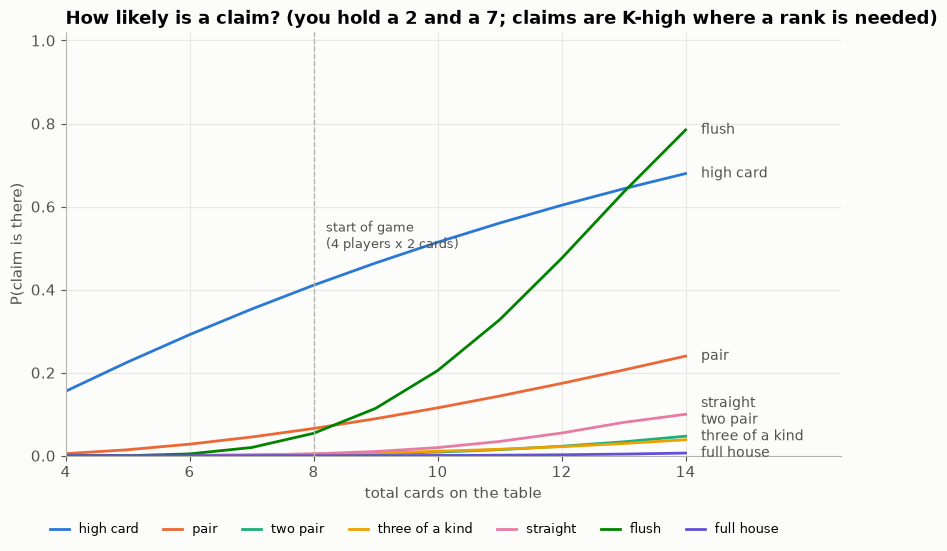

In [23]:
show = [("high card", 13, 0), ("pair", 13, 0), ("two pair", 13, 12), ("three of a kind", 13, 0),
        ("straight", 14, 0), ("flush", 0, 0), ("full house", 13, 12)]
low_hand = [(2, "S"), (7, "H")]
unseen_range = range(2, MAX_UNSEEN + 1)
fig, ax = plt.subplots(figsize=(10, 5.5))
ends = []
for color, claim in zip(SERIES, show):
    x = [u + 2 for u in unseen_range]
    y = [p_true(claim, low_hand, u) for u in unseen_range]
    ax.plot(x, y, color=color, lw=2, label=claim[0])
    ends.append([y[-1], claim[0]])
# space out the end-of-line labels so they don't overlap
ends.sort()
for i in range(1, len(ends)):
    ends[i][0] = max(ends[i][0], ends[i - 1][0] + 0.04)
for y_label, name in ends:
    ax.text(x[-1] + 0.25, y_label, name, va="center", fontsize=10, color="#52514e")
ax.axvline(2 * NUM_PLAYERS, color="#b5b4ad", lw=1, ls="--")
ax.text(2 * NUM_PLAYERS + 0.2, 0.5, f"start of game\n({NUM_PLAYERS} players x 2 cards)", fontsize=9, color="#52514e")
ax.set(xlabel="total cards on the table", ylabel="P(claim is there)", xlim=(4, MAX_UNSEEN + 4.5), ylim=(0, 1.02),
       xticks=range(4, MAX_UNSEEN + 3, 2))
ax.set_title("How likely is a claim? (you hold a 2 and a 7; claims are K-high where a rank is needed)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=7, frameon=False, fontsize=9, handlelength=1.5)
plt.show()

### Graph: your own cards matter a lot
The chance of **three of a kind** in a specific rank, by how many of that rank *you* hold.

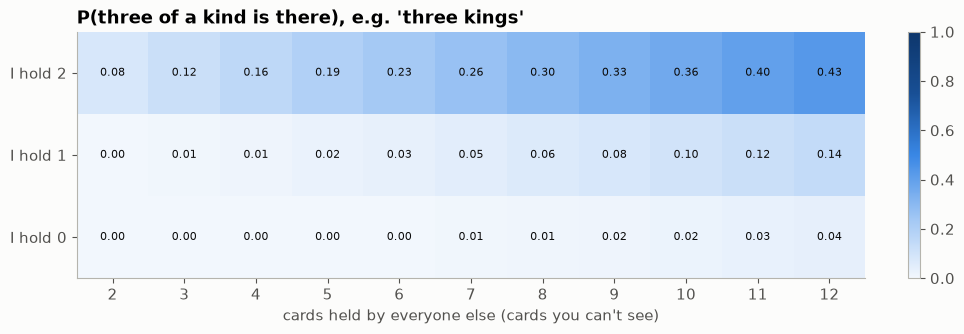

In [24]:
blues = LinearSegmentedColormap.from_list("blues", ["#f2f7fd", "#9ec5f4", "#3987e5", "#184f95", "#0d366b"])
hands = {2: [(13, "S"), (13, "H")], 1: [(13, "S"), (7, "H")], 0: [(2, "S"), (7, "H")]}
tk = pd.DataFrame({u: {h: exact_p(("three of a kind", 13, 0), hand, u) for h, hand in hands.items()}
                   for u in unseen_range})
tk.index.name = "my_help"
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(tk.values, cmap=blues, vmin=0, vmax=1, aspect="auto")
for i in range(tk.shape[0]):
    for j in range(tk.shape[1]):
        v = tk.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.55 else "#0b0b0b")
ax.set_xticks(range(tk.shape[1]), tk.columns)
ax.set_yticks(range(tk.shape[0]), [f"I hold {h}" for h in tk.index])
ax.set_xlabel("cards held by everyone else (cards you can't see)")
ax.grid(False)
ax.set_title("P(three of a kind is there), e.g. 'three kings'", loc="left")
fig.colorbar(im, ax=ax, fraction=0.025)
plt.show()

## 3. Monte Carlo: how risky is a raise?

Calling and raising lose in different ways:
- **CALL** loses if the claim is there: `P(lose) = P(claim is there)`
- **RAISE** loses only if the next player calls you **and** your raise isn't there:
  `P(lose) = P(next player calls AND my raise is false)`

You can't see the next player's cards either, so we use Monte Carlo again. Deal the unseen cards at random,
ask "would the next player call, given *their* cards?", and check whether my raise would hold up.

**How the next player decides:** they estimate the claim from their own cards and are more likely to call
the less likely it looks to them. The model gives a 50% chance of a call at 50% likely, about 90% at 30%,
and about 10% at 70%.

**Which raise?** Each turn, we pick the raise with the lowest risk.

In [25]:
def call_prob(p):
    """Chance a player calls a claim they think is p likely to be true."""
    return 1 / (1 + math.exp((p - 0.5) / 0.08))


CLAIMS_BY_CAT = {cat: [c for c in ALL_CLAIMS if c[0] == cat] for cat in CATEGORIES}


def raise_candidates(current, mine):
    """For each hand type, the cheapest legal raise built from my ranks (plus the cheapest raise overall)."""
    floor = CLAIM_INDEX[current] if current else -1
    my_ranks = sorted({r for r, _ in mine})
    out = []
    for cat in CATEGORIES:
        start = max(CATEGORY_START[cat], floor + 1)
        cands = [ALL_CLAIMS[start]] if start < len(ALL_CLAIMS) and ALL_CLAIMS[start][0] == cat else []
        if cat in ("high card", "pair", "three of a kind", "four of a kind"):
            cands += [(cat, r, 0) for r in my_ranks]
        elif cat in ("two pair", "full house"):
            cands += [(cat, a, b) for a in my_ranks for b in RANKS if a != b and (cat == "full house" or a > b)]
            cands += [(cat, a, b) for b in my_ranks for a in RANKS if a != b and (cat == "full house" or a > b)]
        elif cat in ("straight", "straight flush"):
            cands += CLAIMS_BY_CAT[cat]
        out += [c for c in set(cands) if CLAIM_INDEX[c] > floor]
    return out


def raise_risk(claim, mine, next_n, unseen, samples=25):
    """Monte Carlo estimate of P(next player calls AND my claim is false)."""
    rest = [c for c in DECK if c not in mine]
    next_unseen = len(mine) + unseen - next_n  # cards the next player can't see
    risk = 0.0
    for _ in range(samples):
        others = random.sample(rest, unseen)
        if not claim_is_true(claim, mine + others):
            risk += call_prob(p_true(claim, others[:next_n], next_unseen))
    return risk / samples


def safest_raise(current, mine, next_n, unseen, samples=25):
    """The raise with the lowest risk. We shortlist with the table first, then Monte Carlo the top few."""
    cands = raise_candidates(current, mine)
    if not cands:
        return None, 1.0
    best_per_cat = {}
    for c in cands:
        key = (p_true(c, mine, unseen), -CLAIM_INDEX[c])
        if c[0] not in best_per_cat or key > best_per_cat[c[0]][0]:
            best_per_cat[c[0]] = (key, c)
    shortlist = sorted(best_per_cat.values(), reverse=True)[:4]
    scored = [(raise_risk(c, mine, next_n, unseen, samples), CLAIM_INDEX[c], c) for _, c in shortlist]
    risk, _, best = min(scored)
    return best, risk


mine = [(13, "S"), (13, "H")]
r, risk = safest_raise(("pair", 11, 0), mine, next_n=2, unseen=2 * (NUM_PLAYERS - 1), samples=400)
print(f"holding K K, over 'pair of Js': safest raise is {claim_name(r)}, risk {risk:.2f}")

holding K K, over 'pair of Js': safest raise is pair of Ks, risk 0.00


## 4. Simulate decisions and record which action actually won

For each simulated turn:
- pick random seats (2 to `NUM_PLAYERS` players left, each holding 2 to 4 cards) and a random current claim
- compute what *I* can know: P(claim is there), the safest raise, and its risk
- deal the real cards, then play out **both** choices: does calling win? Does raising win?

When both choices give the same result (both win or both lose), that deal can't tell us which is better,
so we drop it. What's left is labeled with the winning action.

In [26]:
def deal_situation():
    n_players = random.randint(2, NUM_PLAYERS)
    counts = [random.randint(2, 4) for _ in range(n_players)]  # counts[0] = me, counts[1] = next player
    table = random.sample(DECK, sum(counts))
    return counts, table


def features_for(mine, claim, counts, samples=25):
    total, unseen = sum(counts), sum(counts) - len(mine)
    r, risk = safest_raise(claim, mine, counts[1], unseen, samples)
    h = my_help(claim, mine)
    return r, {
        "claim_level": CATEGORIES.index(claim[0]),
        "my_help": h,
        "still_needed": CARDS_NEEDED[claim[0]] - h,
        "my_cards": len(mine),
        "total_cards": total,
        "players_left": len(counts),
        "p_claim_true": round(p_true(claim, mine, unseen), 3),
        "p_raise_true": round(p_true(r, mine, unseen), 3) if r else 0.0,
        "raise_risk": round(risk, 3),
    }


def simulate_decisions(n_rows):
    rows, dealt = [], 0
    while len(rows) < n_rows:
        dealt += 1
        counts, table = deal_situation()
        mine, nxt = table[:counts[0]], table[counts[0]:counts[0] + counts[1]]
        claim = random_claim(mine)
        r, feats = features_for(mine, claim, counts)
        if r is None:
            continue
        lose_call = claim_is_true(claim, table)
        next_calls = random.random() < call_prob(p_true(r, nxt, len(table) - len(nxt)))
        lose_raise = next_calls and not claim_is_true(r, table)
        if lose_call == lose_raise:
            continue
        rows.append({**feats, "action": "RAISE" if lose_call else "CALL"})
    print(f"kept {n_rows:,} of {dealt:,} simulated turns")
    return pd.DataFrame(rows)


start = time.time()
df = simulate_decisions(20_000)
print(f"{time.time() - start:.0f}s")
print(df["action"].value_counts(normalize=True).round(3))
df.head()

kept 20,000 of 25,914 simulated turns
48s
action
CALL     0.87
RAISE    0.13
Name: proportion, dtype: float64


,claim_level,my_help,still_needed,my_cards,total_cards,players_left,p_claim_true,p_raise_true,raise_risk,action
0,7,1,3,2,8,3,0.001,0.000,0.998,CALL
1,5,2,3,3,7,3,0.033,0.002,0.998,CALL
2,5,2,3,3,5,2,0.000,0.000,0.998,CALL
3,4,2,3,4,7,2,0.005,0.010,0.996,CALL
4,8,1,4,3,12,4,0.001,0.005,0.998,CALL


### Graph: the data confirms the theory
Each cell groups simulated turns by **P(claim is there)** and **risk of raising**. The color shows how often
raising was the right move. Theory says to raise when the claim is more likely than your raise risk,
which is everything below the dashed line.

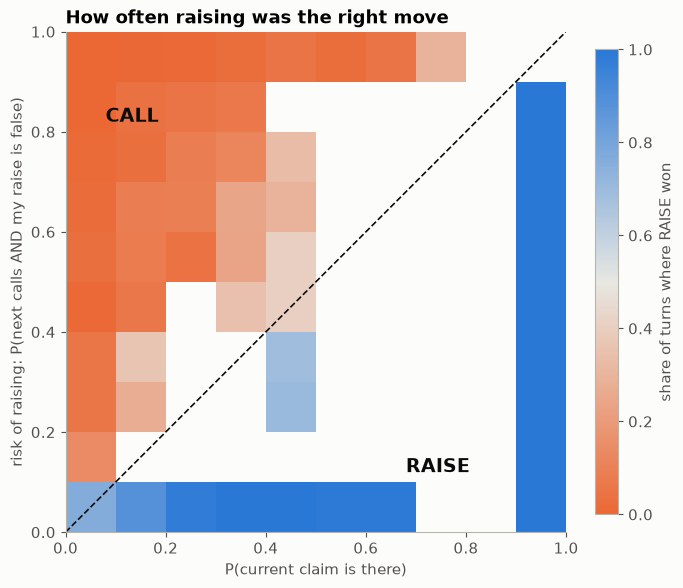

In [27]:
bins = np.linspace(0, 1, 11)
grid = (df.assign(px=pd.cut(df.p_claim_true, bins, include_lowest=True, labels=False),
                  ry=pd.cut(df.raise_risk, bins, include_lowest=True, labels=False),
                  raise_right=df.action.eq("RAISE"))
          .groupby(["ry", "px"]).agg(rate=("raise_right", "mean"), n=("raise_right", "size")).reset_index())
grid = grid[grid.n >= 15]
mat = np.full((10, 10), np.nan)
for g in grid.itertuples():
    mat[int(g.ry), int(g.px)] = g.rate

# same colors as the tree plots below: orange = CALL, blue = RAISE
diverging = LinearSegmentedColormap.from_list("div", [ORANGE, "#e8e7e2", BLUE])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(mat, origin="lower", extent=(0, 1, 0, 1), cmap=diverging, vmin=0, vmax=1)
ax.plot([0, 1], [0, 1], ls="--", color="#0b0b0b", lw=1.2)
ax.text(0.68, 0.12, "RAISE", fontsize=14, fontweight="bold", color="#0b0b0b")
ax.text(0.08, 0.82, "CALL", fontsize=14, fontweight="bold", color="#0b0b0b")
ax.set(xlabel="P(current claim is there)", ylabel="risk of raising: P(next calls AND my raise is false)")
ax.grid(False)
ax.set_title("How often raising was the right move", loc="left")
cb = fig.colorbar(im, ax=ax, fraction=0.04)
cb.set_label("share of turns where RAISE won")
plt.show()

## 5. Train the trees

**Tree A, rules of thumb:** only uses things you can count at the table (claim type, how many of your cards
help, how many cards are out). You could memorize it.

**Tree B, the calculator:** uses the Monte Carlo probabilities. It's more accurate, but you need the computer.

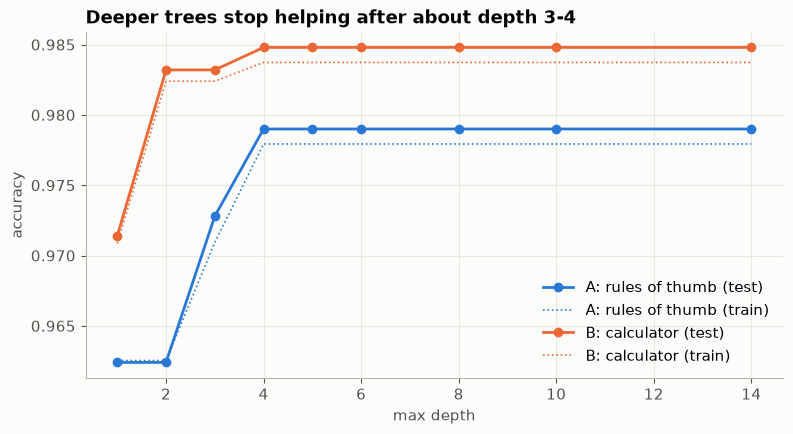

In [28]:
features_a = ["claim_level", "my_help", "still_needed", "my_cards", "total_cards", "players_left"]
features_b = ["p_claim_true", "p_raise_true", "raise_risk", "total_cards", "my_cards"]

train, test = train_test_split(df, test_size=0.25, random_state=163)

depths = [1, 2, 3, 4, 5, 6, 8, 10, 14]
curves = {}
for name, feats in [("A: rules of thumb", features_a), ("B: calculator", features_b)]:
    curves[name] = [(d, accuracy_score(train.action, (m := DecisionTreeClassifier(max_depth=d, min_samples_leaf=50,
                     random_state=163).fit(train[feats], train.action)).predict(train[feats])),
                     accuracy_score(test.action, m.predict(test[feats]))) for d in depths]

fig, ax = plt.subplots(figsize=(9, 4.5))
for color, (name, pts) in zip([BLUE, ORANGE], curves.items()):
    d, tr, te = zip(*pts)
    ax.plot(d, te, color=color, lw=2, marker="o", ms=6, label=f"{name} (test)")
    ax.plot(d, tr, color=color, lw=1.2, ls=":", label=f"{name} (train)")
ax.set(xlabel="max depth", ylabel="accuracy")
ax.set_title("Deeper trees stop helping after about depth 3-4", loc="left")
ax.legend(frameon=False)
plt.show()

In [29]:
tree_a = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=163).fit(train[features_a], train.action)
tree_b = DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=163).fit(train[features_b], train.action)
print(f"Tree A test accuracy: {accuracy_score(test.action, tree_a.predict(test[features_a])):.3f}")
print(f"Tree B test accuracy: {accuracy_score(test.action, tree_b.predict(test[features_b])):.3f}")
print(f"Always CALL baseline: {(test.action == 'CALL').mean():.3f}")

Tree A test accuracy: 0.973
Tree B test accuracy: 0.985
Always CALL baseline: 0.874


### Tree A: rules of thumb
`claim_level`: 0 = high card, 1 = pair, 2 = two pair, 3 = three of a kind, 4 = straight, 5 = flush,
6 = full house, 7 = four of a kind, 8 = straight flush.

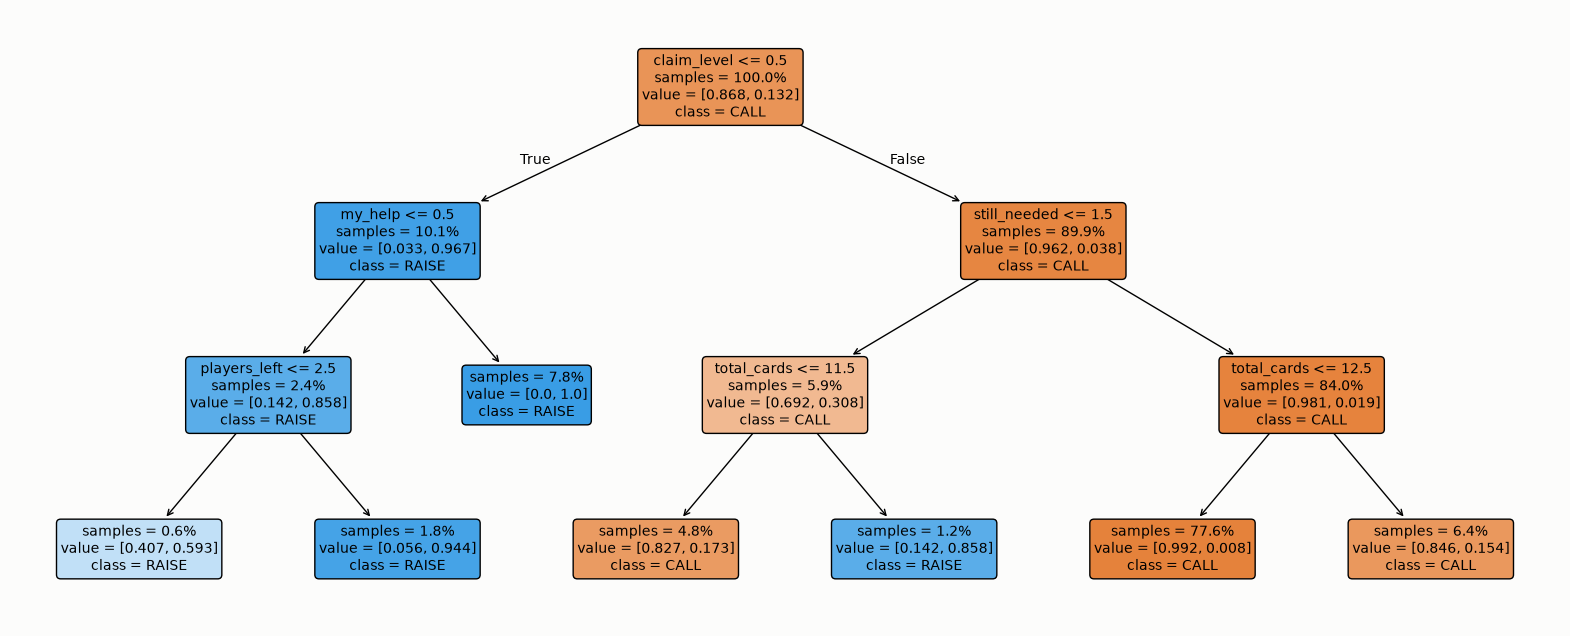

|--- claim_level <= 0.50
|   |--- my_help <= 0.50
|   |   |--- players_left <= 2.50
|   |   |   |--- class: RAISE
|   |   |--- players_left >  2.50
|   |   |   |--- class: RAISE
|   |--- my_help >  0.50
|   |   |--- class: RAISE
|--- claim_level >  0.50
|   |--- still_needed <= 1.50
|   |   |--- total_cards <= 11.50
|   |   |   |--- class: CALL
|   |   |--- total_cards >  11.50
|   |   |   |--- class: RAISE
|   |--- still_needed >  1.50
|   |   |--- total_cards <= 12.50
|   |   |   |--- class: CALL
|   |   |--- total_cards >  12.50
|   |   |   |--- class: CALL



In [30]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree_a, feature_names=features_a, class_names=list(tree_a.classes_), filled=True, rounded=True,
          fontsize=10, impurity=False, proportion=True, ax=ax)
plt.show()
print(export_text(tree_a, feature_names=features_a))

**Tree A in plain English** for the 4-player game (`still_needed` = cards the claim needs that you don't hold
yourself). Some splits have the same answer on both sides; those are leftovers you can ignore.

- The claim is a **high card** → **RAISE**
- The claim needs **at most 1 card** you don't have (like a pair where you hold one of them) → **CALL** with
  11 or fewer cards on the table, **RAISE** with 12 or more
- The claim needs **2 or more cards** you don't have → **CALL**

In other words, call early and raise late. As players lose and pick up cards, claims you'd have called become safe.
With a different `NUM_PLAYERS` the tree changes, so reread the printout above.

### Tree B: the calculator

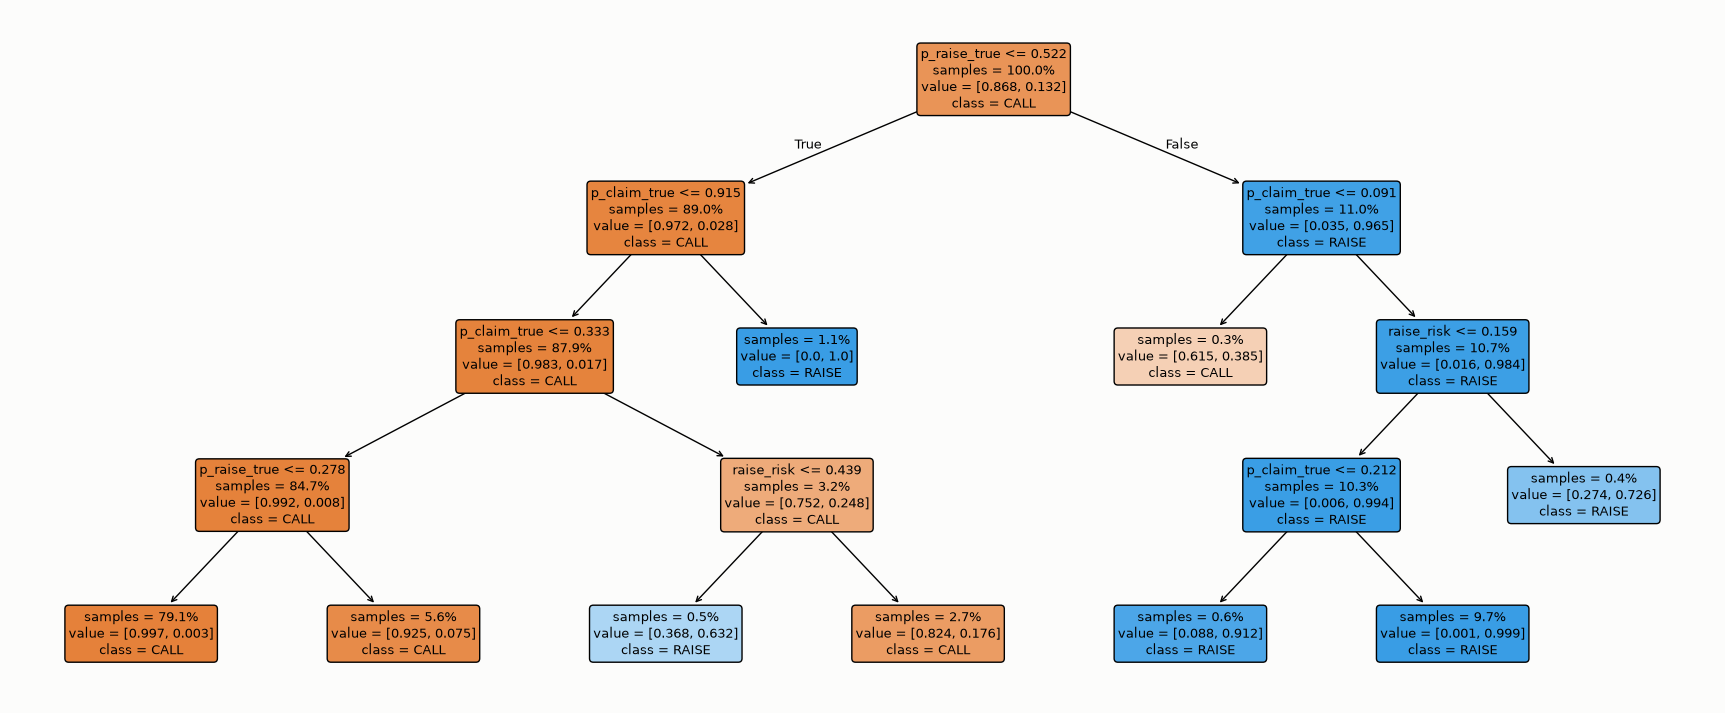

In [31]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree_b, feature_names=features_b, class_names=list(tree_b.classes_), filled=True, rounded=True,
          fontsize=9, impurity=False, proportion=True, ax=ax)
plt.show()

## 6. Play full games

`NUM_PLAYERS` players, each using a different strategy for the call-or-raise choice. Everyone picks their raise the
same way (the safest raise), so the only difference is **when they call**.

| strategy | calls when... |
|---|---|
| Tree B | the tree says CALL |
| Tree A | the rules-of-thumb tree says CALL |
| Bold | P(claim is there) < 20% (almost always raises) |
| 50/50 | P(claim is there) < 50%, ignoring the risk of raising |
| Random | a coin flip says so |

The table uses the first `NUM_PLAYERS` strategies in this list, so with 4 players Random sits out.
Seats are shuffled every game. If every strategy were equally good, each would win 1 / `NUM_PLAYERS` of the games
(25% with 4 players).

In [32]:
def decide(strategy, mine, claim, counts):
    if claim is None:
        return "RAISE"
    r, f = features_for(mine, claim, counts, samples=15)
    if r is None:
        return "CALL"
    if strategy == "Tree B":
        return tree_b.predict(pd.DataFrame([f])[features_b])[0]
    if strategy == "Tree A":
        return tree_a.predict(pd.DataFrame([f])[features_a])[0]
    if strategy == "50/50":
        return "CALL" if f["p_claim_true"] < 0.5 else "RAISE"
    if strategy == "Bold":
        return "CALL" if f["p_claim_true"] < 0.2 else "RAISE"
    return random.choice(["CALL", "RAISE"])


def play_game(strategies):
    players = list(strategies)
    cards = {p: 2 for p in players}
    turn = 0
    while len(players) > 1:
        deck = random.sample(DECK, sum(cards[p] for p in players))
        hands, i = {}, 0
        for p in players:
            hands[p], i = deck[i:i + cards[p]], i + cards[p]
        claim, claimer = None, None
        while True:
            p = players[turn % len(players)]
            order = players[turn % len(players):] + players[:turn % len(players)]
            counts = [cards[q] for q in order]
            if decide(p, hands[p], claim, counts) == "CALL":
                loser = claimer if not claim_is_true(claim, deck) else p
                break
            claim, _ = safest_raise(claim, hands[p], counts[1], sum(counts) - cards[p], samples=15)
            claimer = p
            turn += 1
        cards[loser] += 1
        idx = players.index(loser)
        if cards[loser] >= MAX_CARDS:
            players.remove(loser)
            turn = idx  # next player after the loser starts
        else:
            turn = idx  # the loser starts the next round
    return players[0]


STRATEGIES = ["Tree B", "Tree A", "Bold", "50/50", "Random"][:NUM_PLAYERS]
start = time.time()
wins = Counter()
N_GAMES = 300
for g in range(N_GAMES):
    seats = STRATEGIES[:]
    random.shuffle(seats)
    wins[play_game(seats)] += 1
print(f"{N_GAMES} games in {time.time() - start:.0f}s")
results = pd.Series({s: wins[s] / N_GAMES for s in STRATEGIES}).sort_values()
results

300 games in 60s


50/50     0.000000
Bold      0.283333
Tree B    0.286667
Tree A    0.430000
dtype: float64

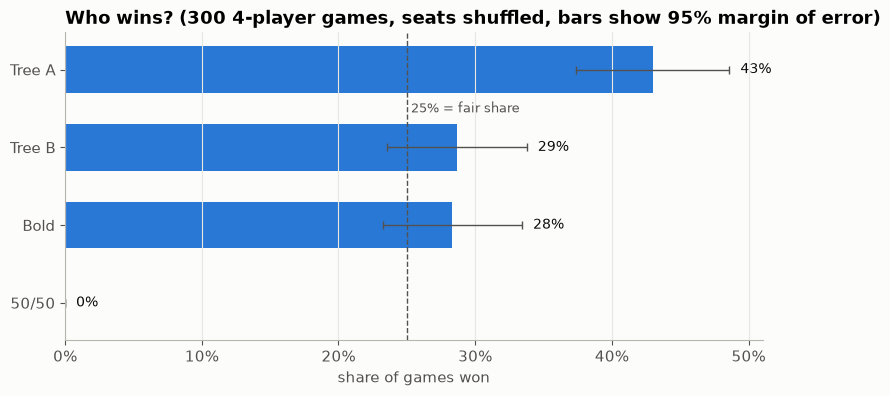

In [33]:
# 95% margin of error for a win rate measured over N_GAMES games
moe = 1.96 * np.sqrt(results * (1 - results) / N_GAMES)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(results.index, results.values, color=BLUE, height=0.6)
ax.errorbar(results.values, range(len(results)), xerr=moe.values, fmt="none", ecolor="#52514e", lw=1, capsize=3)
fair = 1 / NUM_PLAYERS
ax.axvline(fair, color="#52514e", ls="--", lw=1)
ax.text(fair + 0.003, len(results) - 1.5, f"{fair:.0%} = fair share", fontsize=9, color="#52514e", va="center")
for y, (v, e) in enumerate(zip(results.values, moe.values)):
    ax.text(v + e + 0.008, y, f"{v:.0%}", va="center", fontsize=10, color="#0b0b0b")
ax.set(xlabel="share of games won")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_title(f"Who wins? ({N_GAMES} {NUM_PLAYERS}-player games, seats shuffled, bars show 95% margin of error)", loc="left")
plt.show()

**Things to notice** (from the 4-player run; other settings will differ)
- **50/50 never wins.** Calling a claim that's 40% likely is a bad bet whenever you have a safe raise available.
- **Tree A (rules of thumb) wins the most**, clearly above its 25% fair share. Tree B and Bold are both close to
  fair share. In the 5-player version Tree B won the most, so the best strategy depends on the table.
- Check the error bars before reading too much into small gaps, or run more games.
- Tree B was trained against a *model* of the next player (the call-probability curve in section 3), not against
  these opponents. That's the likely reason the more "accurate" tree doesn't win more: 98.5% accuracy on simulated
  turns doesn't help if the simulated opponent doesn't play like the real ones. A tree is only as good as the
  simulation that made its training data.

**Try it:** change `call_prob` so opponents call more or less often, retrain, and see whether the tree adapts.
Or have the tree play against copies of itself.

## 7. Ask the tree about your own hand

Cards are written as rank + suit: `KS` = king of spades, `10H` or `TH` = ten of hearts, `AD`, `2C`.

Edit the cell below, or use the form under it.

In [34]:
RANK_PARSE = {**{str(r): r for r in range(2, 11)}, "T": 10, "J": 11, "Q": 12, "K": 13, "A": 14}


def parse_cards(text):
    cards = []
    for tok in text.replace(",", " ").upper().split():
        rank, suit = RANK_PARSE[tok[:-1]], tok[-1]
        assert suit in SUITS, f"bad suit in {tok}"
        cards.append((rank, suit))
    assert len(set(cards)) == len(cards), "duplicate card"
    return cards


def advise(my_cards, claim, others):
    """
    my_cards: e.g. "KS KH"
    claim:    e.g. ("three of a kind", 13, 0), or None if you are opening
    others:   card counts of the other players still in, starting with the NEXT player, e.g. [2, 3, 2]
    """
    mine = parse_cards(my_cards)
    counts = [len(mine)] + list(others)
    total, unseen = sum(counts), sum(counts) - len(mine)
    print(f"You hold {my_cards.upper()} | {len(counts)} players, {total} cards on the table")
    if claim is None:
        r, risk = safest_raise(None, mine, counts[1], unseen, samples=300)
        print(f"You're opening. Safest claim: {claim_name(r)} (risk {risk:.0%})")
        return
    r, risk = safest_raise(claim, mine, counts[1], unseen, samples=300)
    p_claim = mc_p_true(claim, mine, unseen, trials=4000)
    f = {"p_claim_true": p_claim, "p_raise_true": mc_p_true(r, mine, unseen, 2000) if r else 0.0,
         "raise_risk": risk, "total_cards": total, "my_cards": len(mine)}
    action = tree_b.predict(pd.DataFrame([f])[features_b])[0] if r else "CALL"
    print(f"Claim: {claim_name(claim)}")
    print(f"  P(claim is there)       = {p_claim:.0%}   <- your chance of losing if you CALL")
    if r:
        print(f"  safest raise            = {claim_name(r)}")
        print(f"  P(called AND it's false) = {risk:.0%}   <- your chance of losing if you RAISE")
    print(f"  Tree says: {action}")


advise("KS KH", ("three of a kind", 13, 0), others=[2] * (NUM_PLAYERS - 1))
print()
advise("4S 9H", ("three of a kind", 13, 0), others=[2] * (NUM_PLAYERS - 1))
print()
advise("4S 9H 9D QC", ("pair", 11, 0), others=[4, 3, 4])
print()
advise("10H 9H", None, others=[2] * (NUM_PLAYERS - 1))

You hold KS KH | 4 players, 8 cards on the table
Claim: three Ks
  P(claim is there)       = 23%   <- your chance of losing if you CALL
  safest raise            = a flush
  P(called AND it's false) = 96%   <- your chance of losing if you RAISE
  Tree says: CALL

You hold 4S 9H | 4 players, 8 cards on the table
Claim: three Ks
  P(claim is there)       = 1%   <- your chance of losing if you CALL
  safest raise            = a flush
  P(called AND it's false) = 95%   <- your chance of losing if you RAISE
  Tree says: CALL

You hold 4S 9H 9D QC | 4 players, 15 cards on the table
Claim: pair of Js
  P(claim is there)       = 23%   <- your chance of losing if you CALL
  safest raise            = a flush
  P(called AND it's false) = 0%   <- your chance of losing if you RAISE
  Tree says: RAISE

You hold 10H 9H | 4 players, 8 cards on the table
You're opening. Safest claim: a 9 (risk 0%)


### Form
Pick the claim, type your cards and the other players' card counts (next player first), then click **Advise**.

In [35]:
import ipywidgets as w
from IPython.display import display

rank_opts = [(RANK_NAME[r], r) for r in RANKS]
cards_box = w.Text(value="KS KH", description="My cards")
others_box = w.Text(value=" ".join(["2"] * (NUM_PLAYERS - 1)), description="Others")
cat_box = w.Dropdown(options=["(opening)"] + CATEGORIES, value="three of a kind", description="Claim")
r1_box = w.Dropdown(options=rank_opts, value=13, description="Rank")
r2_box = w.Dropdown(options=rank_opts, value=2, description="2nd rank")
go = w.Button(description="Advise", button_style="primary")
out = w.Output()


def on_click(_):
    out.clear_output()
    with out:
        try:
            cat = cat_box.value
            if cat == "(opening)":
                claim = None
            elif cat == "flush":
                claim = ("flush", 0, 0)
            elif cat in ("two pair", "full house"):
                claim = (cat, r1_box.value, r2_box.value)
            else:
                claim = (cat, r1_box.value, 0)
            advise(cards_box.value, claim, [int(x) for x in others_box.value.replace(",", " ").split()])
        except Exception as e:
            print("Problem:", e)


go.on_click(on_click)
display(w.VBox([cards_box, others_box, cat_box, w.HBox([r1_box, r2_box]), go, out]))